# CPI Cost Forecasting: Baselines vs Statistical and ML Models

**Driving question:** if a finance team needs a 12-month forecast of monthly cost indices, can statistical or machine learning models beat simple baselines reliably, and how much should the forecast ranges be trusted?

**Data:** five US CPI series from FRED (All items, Food, Energy, Apparel, Medical care), monthly, not seasonally adjusted, 2010-01 to 2026-09. CPI is used as a public proxy for cost indices; it is not company cost data.

**Structure:** forecasting and evaluation code lives in `data_utils.py`, `models.py`, `metrics.py` and `backtest.py`, with unit tests in `tests/`. This notebook runs the analysis and reports results.

## 1. Setup and Data

In [5]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from backtest import make_splits, run_backtest, run_interval_backtest
from data_utils import fetch_and_cache, load_cpi, report_missing
from metrics import calc_mae, calc_mase
from models import (
    AUDIT_STATUSES,
    drift_forecast,
    ets_forecast_audited,
    ml_hgb_forecast,
    naive_forecast,
    sarima_forecast_audited,
    seasonal_naive_forecast,
)

DATA_DIR, RESULTS_DIR, PLOTS_DIR = "data", "results", "plots"
for folder in (DATA_DIR, RESULTS_DIR, PLOTS_DIR):
    os.makedirs(folder, exist_ok=True)

CUTOFFS = ["2022-09-01", "2023-09-01", "2024-09-01", "2025-09-01"]
HORIZON = 12

csv_filename = os.path.join(DATA_DIR, "cpi_data.csv")
if not os.path.exists(csv_filename):
    fetch_and_cache(csv_filename)

df = load_cpi(csv_filename)
report_missing(df)
df.head()

Range: 2010-01 to 2026-09 (201 months)
NaN count per column:
All_Items       1
Food            1
Energy          1
Apparel         1
Medical_Care    1
dtype: int64
Months with missing values: ['2025-10']


,All_Items,Food,Energy,Apparel,Medical_Care
Date,,,,,
2010-01-01,216.687,218.874,208.026,116.678,382.688
2010-02-01,216.741,218.778,204.455,118.869,385.907
2010-03-01,217.631,219.032,209.999,122.073,387.142
2010-04-01,218.009,219.218,212.977,122.143,387.703
2010-05-01,218.178,219.374,214.363,121.006,387.762


**Missing month:** 2025-10 is empty in all five series in the source data. It is kept as a NaN row rather than dropped or filled, so that row position always equals calendar time (a 12-month lag always points to the same month one year earlier). Months with no actual value are excluded from every error and coverage calculation.

## 2. Exploratory Analysis

### 2.1 Level, MoM and YoY Changes

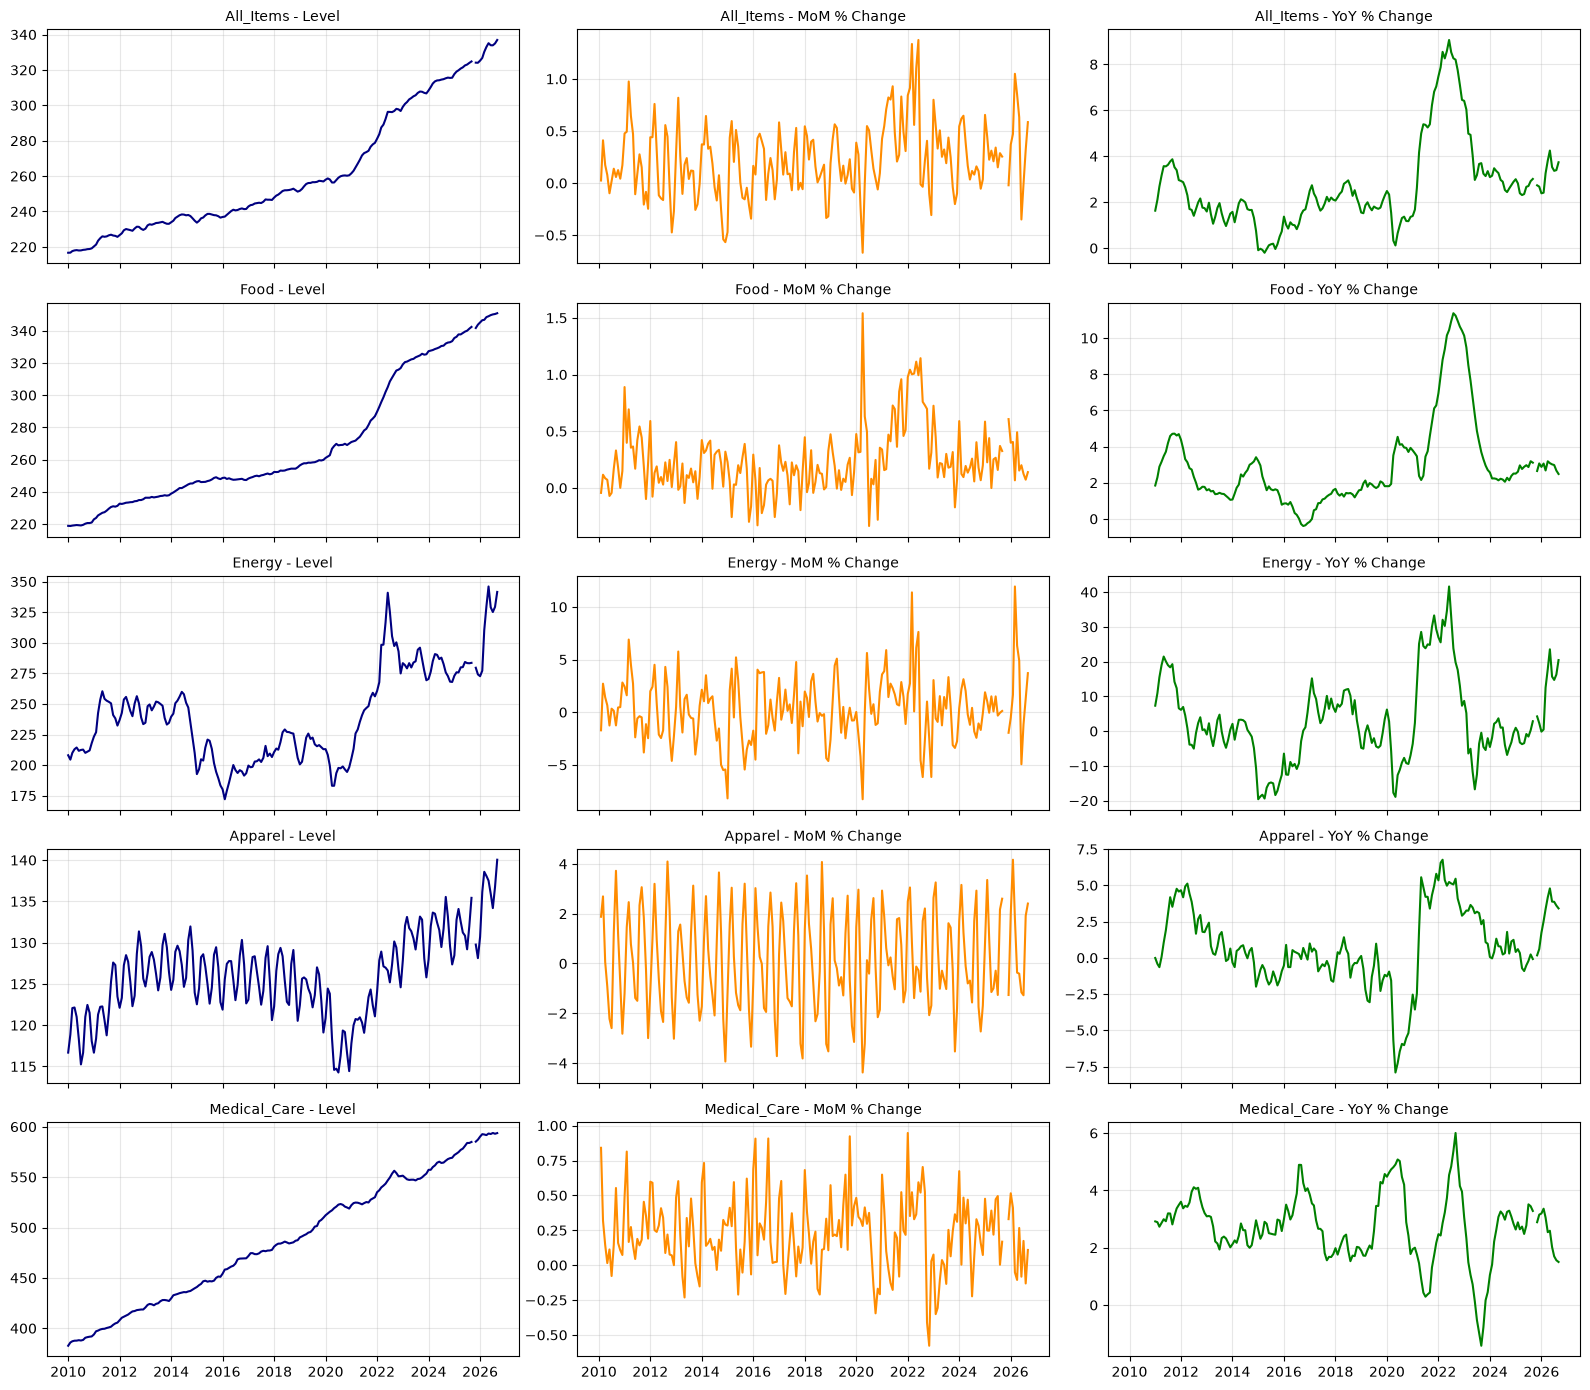

In [6]:
fig, axes = plt.subplots(5, 3, figsize=(16, 14), sharex=True)

for i, col in enumerate(df.columns):
    # Level
    axes[i, 0].plot(df.index, df[col], color='navy')
    axes[i, 0].set_title(f"{col} - Level", fontsize=10)
    axes[i, 0].grid(True, alpha=0.3)

    # Monthly Change % (MoM)
    axes[i, 1].plot(df.index, df[col].pct_change(fill_method=None) * 100, color='darkorange')
    axes[i, 1].set_title(f"{col} - MoM % Change", fontsize=10)
    axes[i, 1].grid(True, alpha=0.3)
    
    # Yearly Change % (YoY)
    axes[i, 2].plot(df.index, df[col].pct_change(12, fill_method=None) * 100, color='green')
    axes[i, 2].set_title(f"{col} - YoY % Change", fontsize=10)
    axes[i, 2].grid(True, alpha=0.3)

plt.tight_layout()

save_path = os.path.join(PLOTS_DIR, "01_cpi_series_level_mom_yoy.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

### 2.2 Monthly Seasonal Profile

The y-axis is shared across panels, so the small month-to-month patterns of All_Items, Food and Medical_Care are hard to see next to Energy and Apparel.

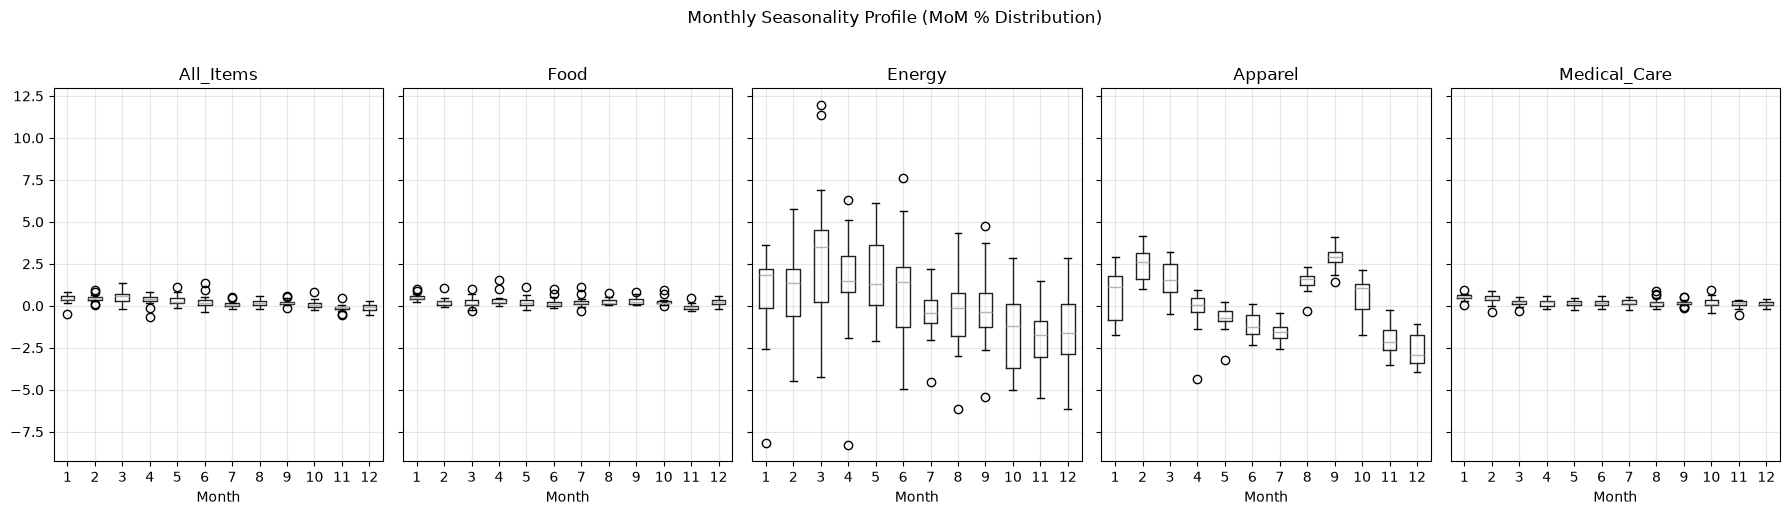

In [7]:
# Seasonal Profile (MoM % by Month)
df_mom = (df.pct_change(fill_method=None) * 100).copy()
df_mom["Month"] = df_mom.index.month

fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=True)
for i, col in enumerate(df.columns):
    df_mom.boxplot(column=col, by="Month", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Month")
    axes[i].grid(True, alpha=0.3)

plt.suptitle("Monthly Seasonality Profile (MoM % Distribution)", y=1.02)
plt.tight_layout()

save_path = os.path.join(PLOTS_DIR, "02_monthly_seasonality_boxplots.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

### 2.3 Seasonal Decomposition

Classical additive decomposition on data up to 2025-09 (it cannot handle the 2025-10 gap). Note that this method forces the seasonal component to repeat identically every year, so a regular seasonal pattern in these plots is a property of the method, not evidence that seasonality is stable.

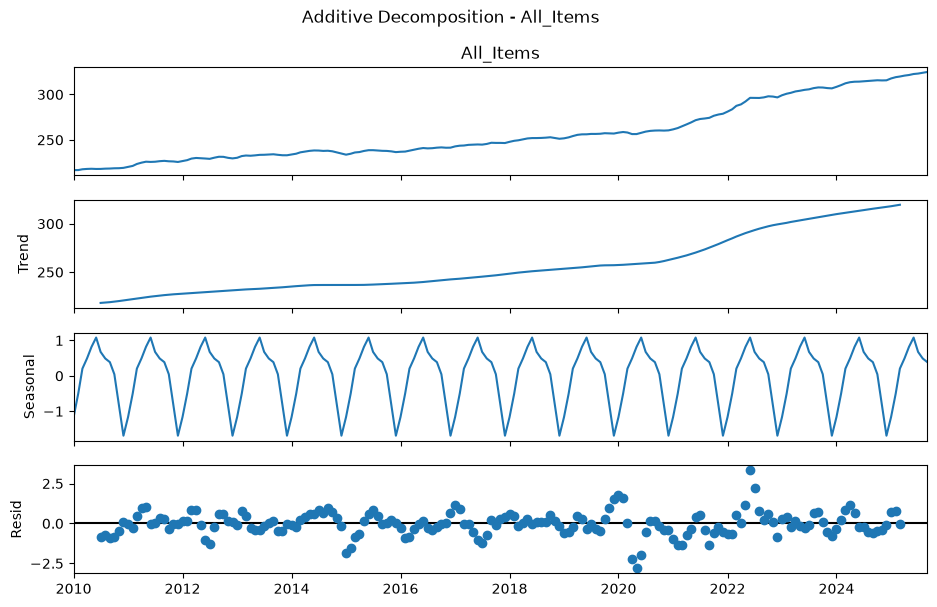

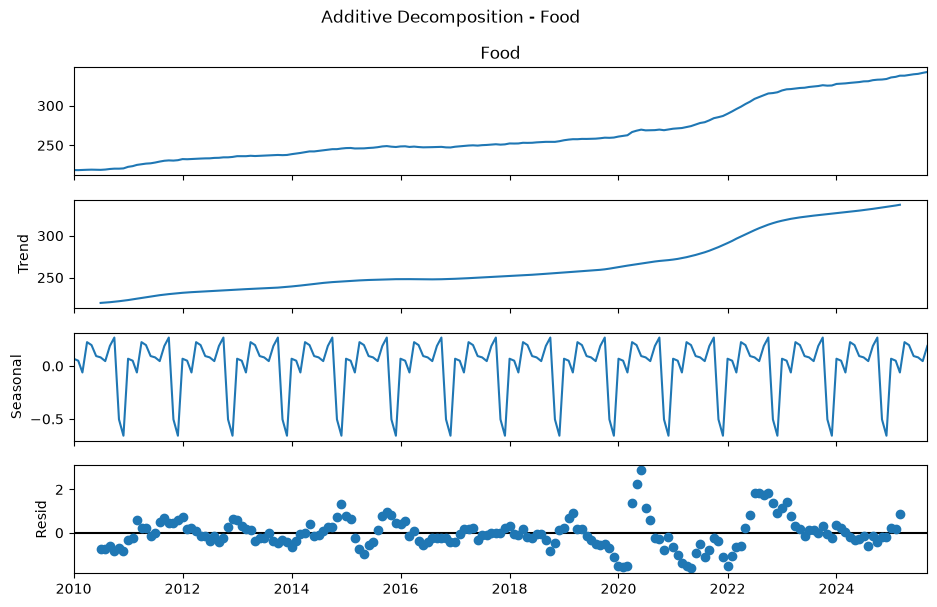

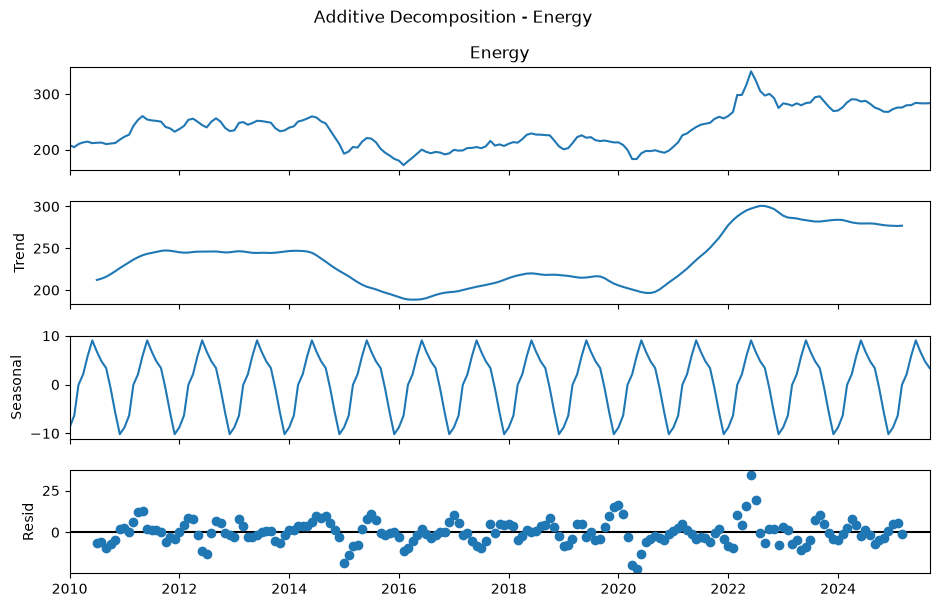

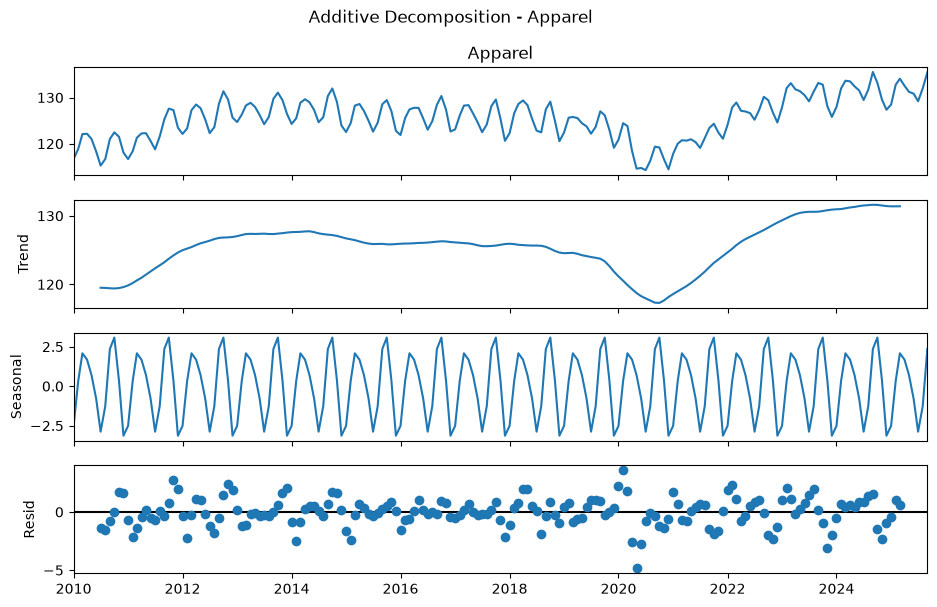

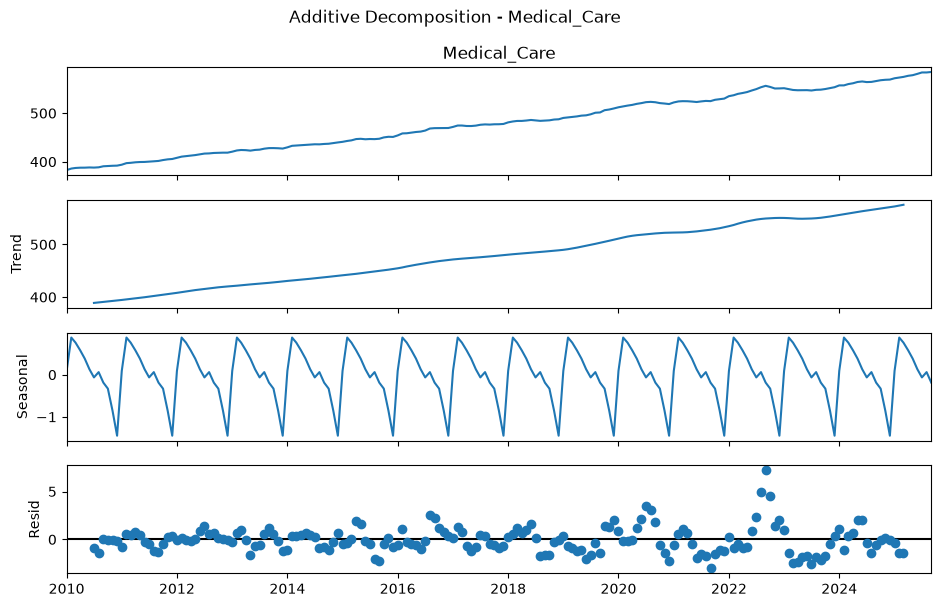

In [8]:
# Classical Additive Decomposition (Ending at 2025-09 to avoid NaNs)
from statsmodels.tsa.seasonal import seasonal_decompose

df_valid = df.loc[:"2025-09-01"]

for col in df.columns:
    decomp = seasonal_decompose(df_valid[col], model="additive", period=12)
    fig = decomp.plot()
    fig.suptitle(f"Additive Decomposition - {col}", y=1.02)
    fig.set_size_inches(10, 6)

    img_name = f"03_decomposition_{col.lower()}.png"
    fig.savefig(os.path.join(PLOTS_DIR, img_name), dpi=300, bbox_inches="tight")
    plt.show()

**EDA summary (visual inspection):**
- All_Items, Food and Medical_Care trend upward over the whole period. All_Items and Food grow faster around 2021-2023, while Medical_Care grows steadily and flattens around 2022-2023. Their monthly seasonal effects are small compared with the trend.
- Apparel has the clearest monthly pattern in the MoM boxplots (higher in February and September, lower in November and December), with a drop around 2020.
- Energy has the widest MoM spread and no stable trend: it fell around 2014-2016 and spiked in 2022.
- The residuals of all series are larger around 2020 and 2022.

## 3. Backtest Design

- **Rolling origin:** four cutoffs (2022-09, 2023-09, 2024-09, 2025-09). Each model is trained only on data up to the cutoff and forecasts the next 12 months.
- **Metrics:** MAE (in index points) and MASE, where MASE scales the test MAE by the in-sample seasonal naive MAE on the training data. MASE below 1 means the forecast error is smaller than that in-sample benchmark; it allows comparison across series with different index levels.
- **Missing values:** months with no actual value are skipped, so the 2025-09 cutoff has 11 evaluated points per series instead of 12 (47 points per series and model in total).
- **Tests:** unit tests on synthetic series with known answers are in `tests/` (`pytest -m "not slow"`), including checks that models only see training data.

## 4. Milestone 1: Baselines

Three baselines: **Naive** (repeat the last value), **Seasonal Naive** (same month last year) and **Drift** (last value plus the average monthly change over the training period).

### 4.1 Backtest Results

In [9]:
# Baseline models (cutoffs and horizon are defined in the setup cell)
models = {
    "Naive": naive_forecast,
    "SeasonalNaive": seasonal_naive_forecast,
    "Drift": drift_forecast
}

# Run Backtest
df_results = run_backtest(df, models, CUTOFFS, horizon=HORIZON)

# Save full long-format table to CSV
csv_save_path = os.path.join(RESULTS_DIR, "milestone1_backtest_results.csv")
df_results.to_csv(csv_save_path, index=False)
print(f"Results successfully saved to: {csv_save_path}")

# Display full table to verify n_points
print("=== Backtest Full Results Table ===")
display(df_results)

Results successfully saved to: results\milestone1_backtest_results.csv
=== Backtest Full Results Table ===


,series,cutoff,model,mae,mase,n_points
0,All_Items,2022-09-01,Naive,5.483083,0.922347,12
1,All_Items,2022-09-01,SeasonalNaive,14.566083,2.450260,12
2,All_Items,2022-09-01,Drift,2.345616,0.394572,12
3,All_Items,2023-09-01,Naive,4.108500,0.620535,12
4,All_Items,2023-09-01,SeasonalNaive,9.291750,1.403398,12
5,All_Items,2023-09-01,Drift,1.359000,0.205259,12
6,All_Items,2024-09-01,Naive,4.695583,0.688993,12
7,All_Items,2024-09-01,SeasonalNaive,8.415583,1.234837,12
8,All_Items,2024-09-01,Drift,1.470729,0.215803,12
9,All_Items,2025-09-01,Naive,6.218818,0.898200,11


In [10]:
# Aggregate MASE distribution across cutoffs per series and model
df_summary_dist = df_results.groupby(["series", "model"])["mase"].agg(
    Mean_MASE="mean",
    Min_MASE="min",
    Max_MASE="max"
).reset_index()

print("=== MASE Distribution across All Cutoffs ===")
display(df_summary_dist)

=== MASE Distribution across All Cutoffs ===


,series,model,Mean_MASE,Min_MASE,Max_MASE
0,All_Items,Drift,0.319962,0.205259,0.464214
1,All_Items,Naive,0.782519,0.620535,0.922347
2,All_Items,SeasonalNaive,1.646545,1.234837,2.450260
3,Apparel,Drift,1.196170,0.730413,1.874110
4,Apparel,Naive,1.148448,0.811194,1.604941
5,Apparel,SeasonalNaive,0.959772,0.280023,1.579253
6,Energy,Drift,0.786972,0.180820,1.486617
7,Energy,Naive,0.742026,0.235033,1.573439
8,Energy,SeasonalNaive,0.867071,0.279700,1.588022
9,Food,Drift,0.217464,0.076504,0.512403


### 4.2 Actual vs Forecast

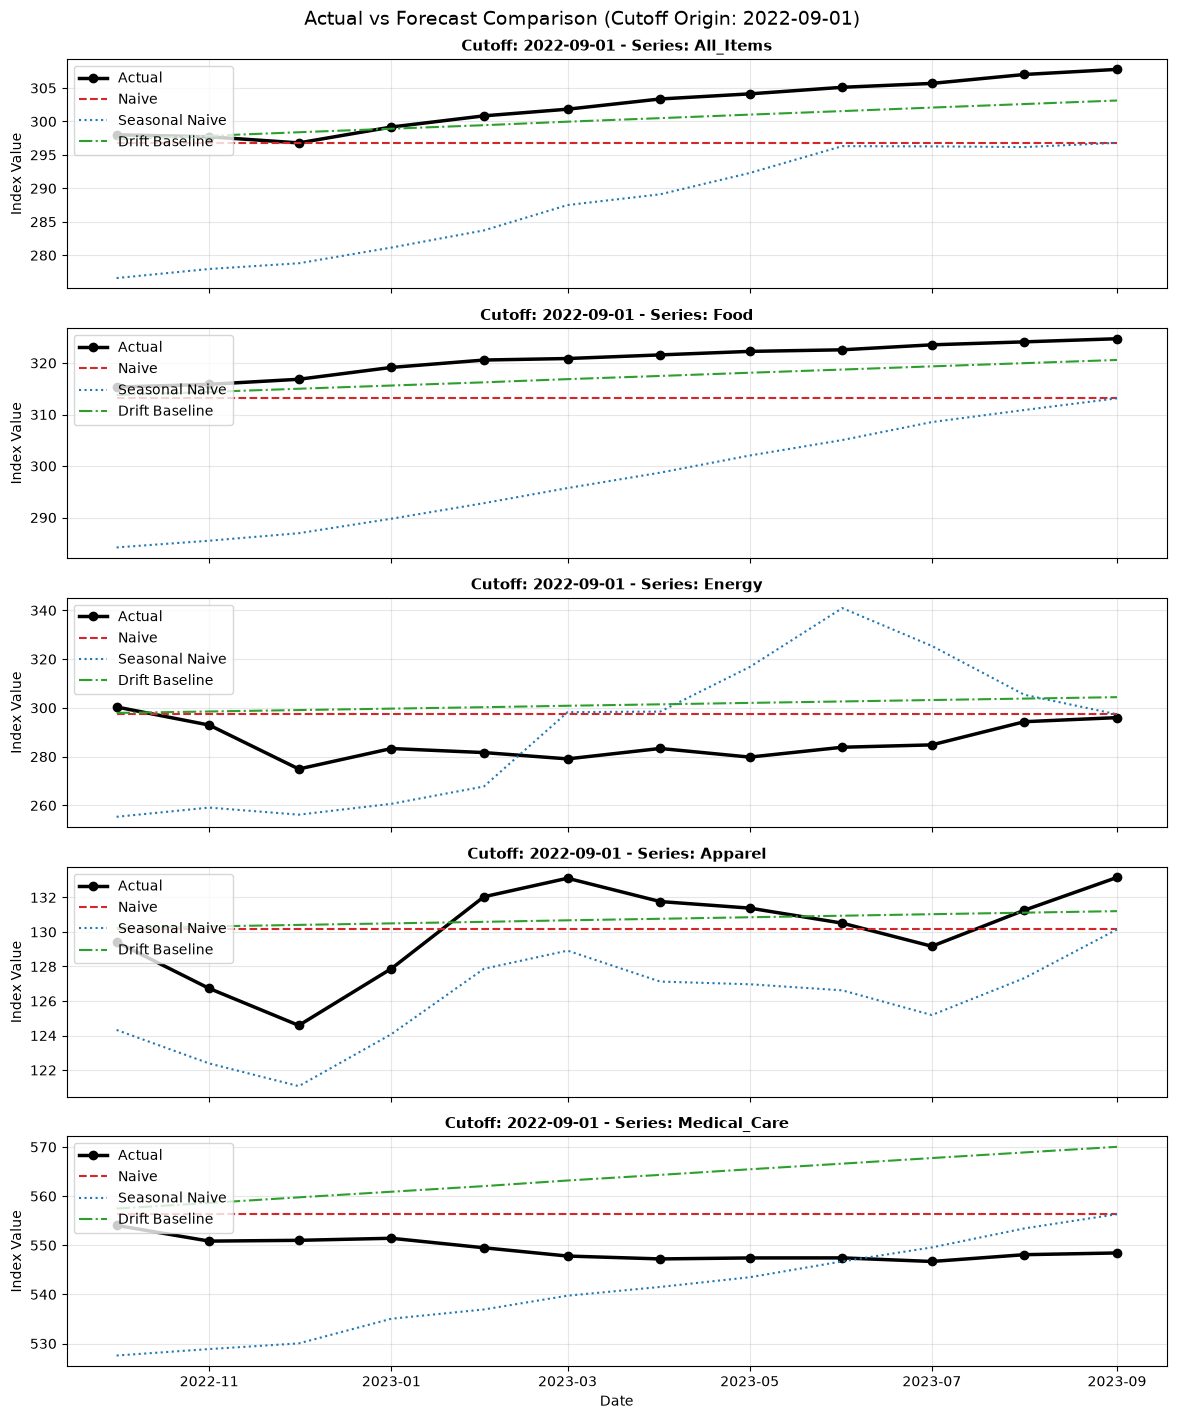

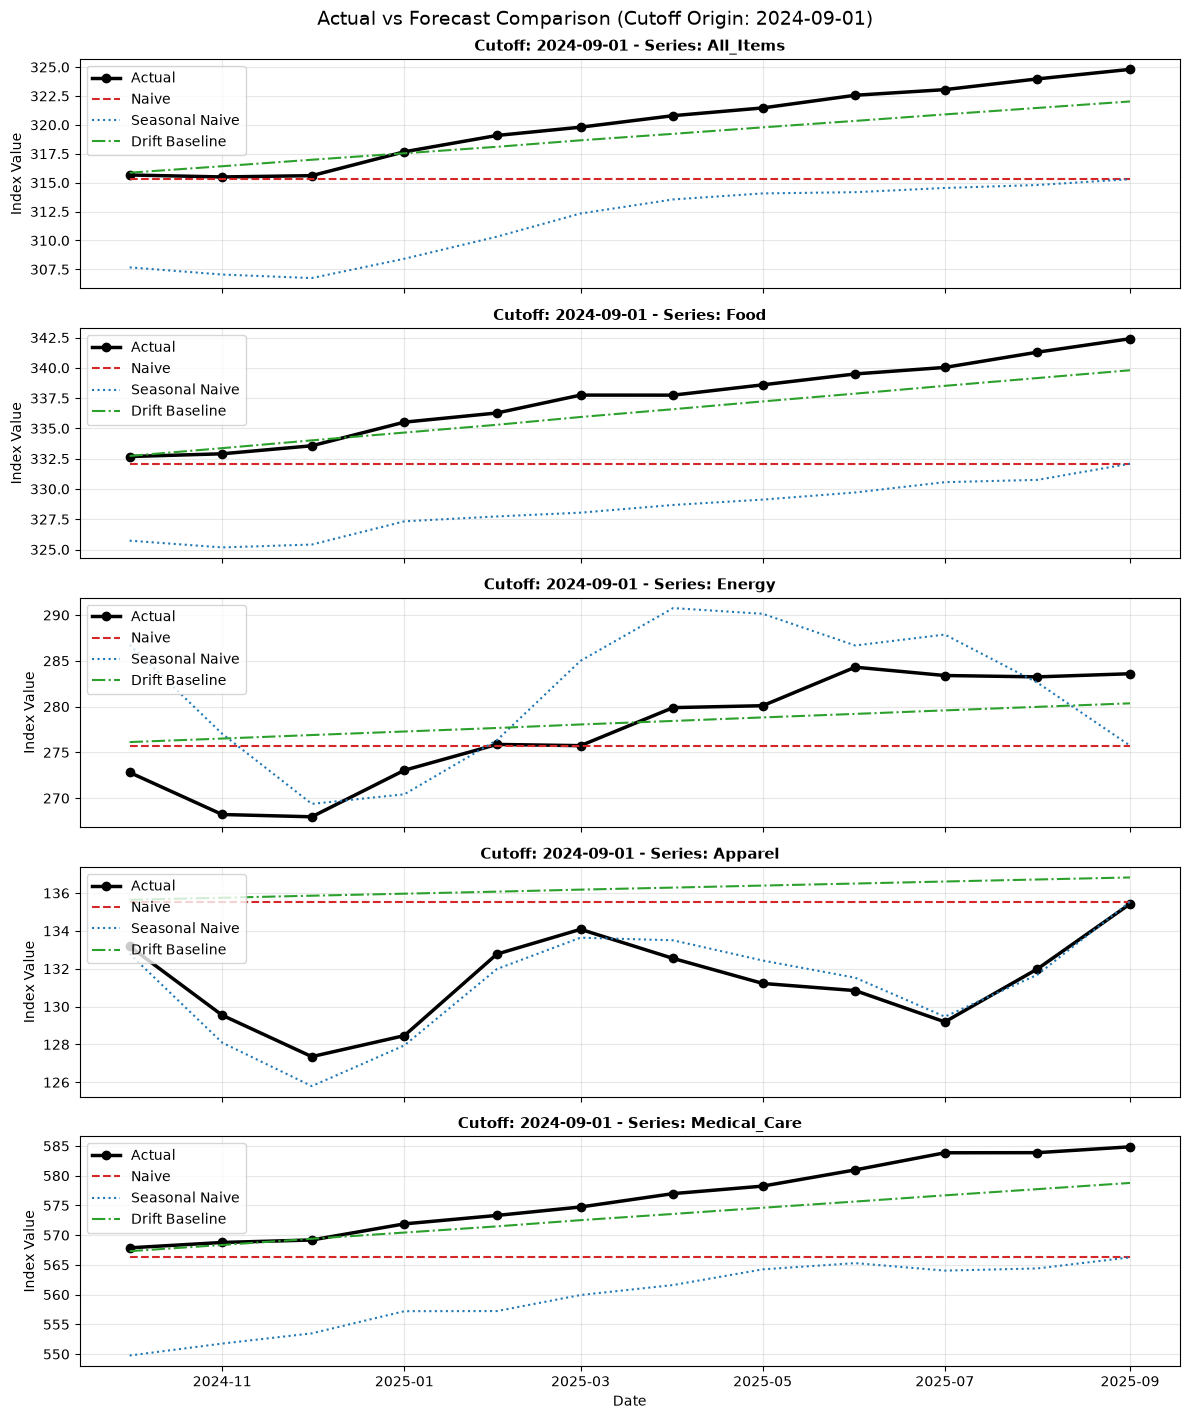

In [11]:
plot_cutoffs = ["2022-09-01", "2024-09-01"]

for cutoff_to_plot in plot_cutoffs:
    fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True)
    
    for i, col in enumerate(df.columns):
        series_data = df[col]
        
        train = series_data.loc[:cutoff_to_plot]
        test_start = pd.to_datetime(cutoff_to_plot) + pd.DateOffset(months=1)
        test_end = pd.to_datetime(cutoff_to_plot) + pd.DateOffset(months=12)
        test = series_data.loc[test_start:test_end]
        
        pred_n = naive_forecast(train, 12)
        pred_sn = seasonal_naive_forecast(train, 12)
        pred_dr = drift_forecast(train, 12)
        
        axes[i].plot(test.index, test, label="Actual", color="black", linewidth=2.5, marker='o')
        axes[i].plot(test.index, pred_n, label="Naive", color="tab:red", linestyle="--")
        axes[i].plot(test.index, pred_sn, label="Seasonal Naive", color="tab:blue", linestyle=":")
        axes[i].plot(test.index, pred_dr, label="Drift Baseline", color="tab:green", linestyle="-.")
        
        axes[i].set_title(f"Cutoff: {cutoff_to_plot} - Series: {col}", fontsize=11, fontweight='bold')
        axes[i].set_ylabel("Index Value")
        axes[i].legend(loc="upper left")
        axes[i].grid(True, alpha=0.3)

    plt.xlabel("Date")
    plt.tight_layout()
    plt.suptitle(f"Actual vs Forecast Comparison (Cutoff Origin: {cutoff_to_plot})", y=1.01, fontsize=14)

    cutoff_str = cutoff_to_plot.replace("-", "")[:6]
    img_name = f"04_actual_vs_forecast_cutoff_{cutoff_str}.png"
    plt.savefig(os.path.join(PLOTS_DIR, img_name), dpi=300, bbox_inches="tight")
    plt.show()

**Milestone 1 summary:**
- **Drift** has the lowest mean MASE for All_Items (0.32), Food (0.22) and Medical_Care (0.47). It is not stable everywhere: for Medical_Care at the 2022-09 cutoff its MASE is 1.13, worse than Naive (0.55).
- **Seasonal Naive** is the weakest baseline on trending series (mean MASE 1.65 for All_Items, 1.68 for Food), because it repeats last year's lower level.
- **Apparel** is the only series where Seasonal Naive has the lowest mean MASE (0.96), winning clearly at 2023-09 and 2024-09 but losing at 2022-09 and 2025-09.
- **Energy:** all three baselines have mean MASE between 0.74 and 0.87, and all are above 1.48 at the 2025-09 cutoff.

## 5. Milestone 2: Statistical and ML Models

### 5.1 Model Specifications

All specifications were fixed before looking at backtest results, except ML (see below).

- **ETS(A,A,A):** additive error, trend and seasonality, 12-month season (`statsmodels` `ETSModel`).
- **SARIMA (0,1,1)(0,1,1,12) with drift:** the "airline" specification (`statsmodels` `SARIMAX`, `trend="c"`).
- **ML_HGB:** `HistGradientBoostingRegressor` predicting the month-over-month change (tree models cannot extrapolate a trend in levels), with lags 1, 2, 3 and 12, a 3-month rolling mean and the month number as features. Multi-step forecasts are recursive, and changes are added back to the last observed level. Features are built inside the model function from training data only.

**ML specification change:** the first run used `max_iter=50, max_depth=3` and default `min_samples_leaf`. A synthetic unit test showed it could not learn a simple seasonal pattern, so it was changed to `max_iter=200, max_depth=4, min_samples_leaf=5`. The change was based on synthetic data, but it was made after seeing the first backtest results. First-run mean MASE: All_Items 0.334, Apparel 0.819, Energy 0.710, Food 0.515, Medical_Care 0.549.

### 5.2 Backtest Results and Convergence Audit

In [12]:
from functools import partial

# Fresh audit lists for THIS backtest run only (re-running the cell resets them)
model_audit_log = {"ETS": [], "SARIMA": []}

all_models_audited = {
    "Naive": naive_forecast,
    "SeasonalNaive": seasonal_naive_forecast,
    "Drift": drift_forecast,
    "ETS": partial(ets_forecast_audited, audit=model_audit_log["ETS"]),
    "SARIMA": partial(sarima_forecast_audited, audit=model_audit_log["SARIMA"]),
    "ML_HGB": ml_hgb_forecast,
}

df_m2_results = run_backtest(df, all_models_audited, CUTOFFS, horizon=HORIZON)

df_m2_results.to_csv(os.path.join(RESULTS_DIR, "milestone2_backtest_results.csv"), index=False)

# Convergence audit report
expected_fits = len(df.columns) * len(CUTOFFS)
audit_frames = []
print("=== Statistical Models Convergence Audit Report ===")
for model_name, records in model_audit_log.items():
    assert len(records) == expected_fits, (
        f"{model_name}: expected {expected_fits} fit records, got {len(records)}"
    )
    df_audit = pd.DataFrame(records)
    df_audit.insert(0, "model", model_name)
    audit_frames.append(df_audit)
    counts = df_audit["status"].value_counts().reindex(AUDIT_STATUSES, fill_value=0)
    summary = ", ".join(f"{k}: {v}/{expected_fits}" for k, v in counts.items())
    print(f"{model_name:<7} - {summary}")

df_audit_all = pd.concat(audit_frames, ignore_index=True)
df_audit_all.to_csv(os.path.join(RESULTS_DIR, "milestone2_fit_audit.csv"), index=False)

problem_fits = df_audit_all[df_audit_all["status"] != "converged"]
if problem_fits.empty:
    print("\nAll fits converged.")
else:
    print("\nFits that did not cleanly converge:")
    display(problem_fits)

=== Statistical Models Convergence Audit Report ===
ETS     - converged: 20/20, not_converged: 0/20, unknown: 0/20, failed: 0/20
SARIMA  - converged: 20/20, not_converged: 0/20, unknown: 0/20, failed: 0/20

All fits converged.


In [13]:
# MASE distribution across cutoffs for all six models
df_m2_summary = (
    df_m2_results.groupby(["series", "model"])
    .agg(Mean_MASE=("mase", "mean"), Max_MASE=("mase", "max"), Mean_MAE=("mae", "mean"))
    .reset_index()
)
display(df_m2_summary)

,series,model,Mean_MASE,Max_MASE,Mean_MAE
0,All_Items,Drift,0.319962,0.464214,2.097350
1,All_Items,ETS,0.289411,0.404647,1.874162
2,All_Items,ML_HGB,0.254608,0.389009,1.651765
3,All_Items,Naive,0.782519,0.922347,5.126496
4,All_Items,SARIMA,0.264234,0.412922,1.732283
5,All_Items,SeasonalNaive,1.646545,2.450260,10.660718
6,Apparel,Drift,1.196170,1.874110,3.088436
7,Apparel,ETS,0.869328,1.085289,2.233166
8,Apparel,ML_HGB,0.931941,1.167992,2.400254
9,Apparel,Naive,1.148448,1.604941,2.957972


### 5.3 Wins vs Best Baseline

A model "wins" a cutoff when its MASE is lower than the best of the three baselines at that cutoff. The best baseline is chosen with hindsight, which a forecaster could not do in practice, so this is a strict benchmark.

In [14]:
# 1. Calculate best baseline MASE per (series, cutoff)
df_baselines = df_m2_results[df_m2_results["model"].isin(["Naive", "SeasonalNaive", "Drift"])]
best_baseline_per_cutoff = (
    df_baselines.groupby(["series", "cutoff"])["mase"]
    .min()
    .reset_index()
    .rename(columns={"mase": "best_baseline_mase"})
)

# 2. Merge back to evaluate main models (ETS, SARIMA, ML_HGB) against best baseline
df_eval = pd.merge(df_m2_results, best_baseline_per_cutoff, on=["series", "cutoff"])
df_eval["beat_best_baseline"] = df_eval["mase"] < df_eval["best_baseline_mase"]

# 3. Pivot table showing count of wins (out of 4 cutoffs) per series
win_count_table = df_eval[df_eval["model"].isin(["ETS", "SARIMA", "ML_HGB"])].groupby(["series", "model"])["beat_best_baseline"].sum().unstack()
win_count_table.columns.name = "Model Wins (Out of 4 Cutoffs)"

print("=== Model Wins vs Best Baseline per Cutoff (Out of 4 Cutoffs) ===")
display(win_count_table)

=== Model Wins vs Best Baseline per Cutoff (Out of 4 Cutoffs) ===


Model Wins (Out of 4 Cutoffs),ETS,ML_HGB,SARIMA
series,,,
All_Items,1,4,2
Apparel,1,1,2
Energy,2,0,2
Food,2,0,1
Medical_Care,2,1,1


### 5.4 Actual vs Forecast

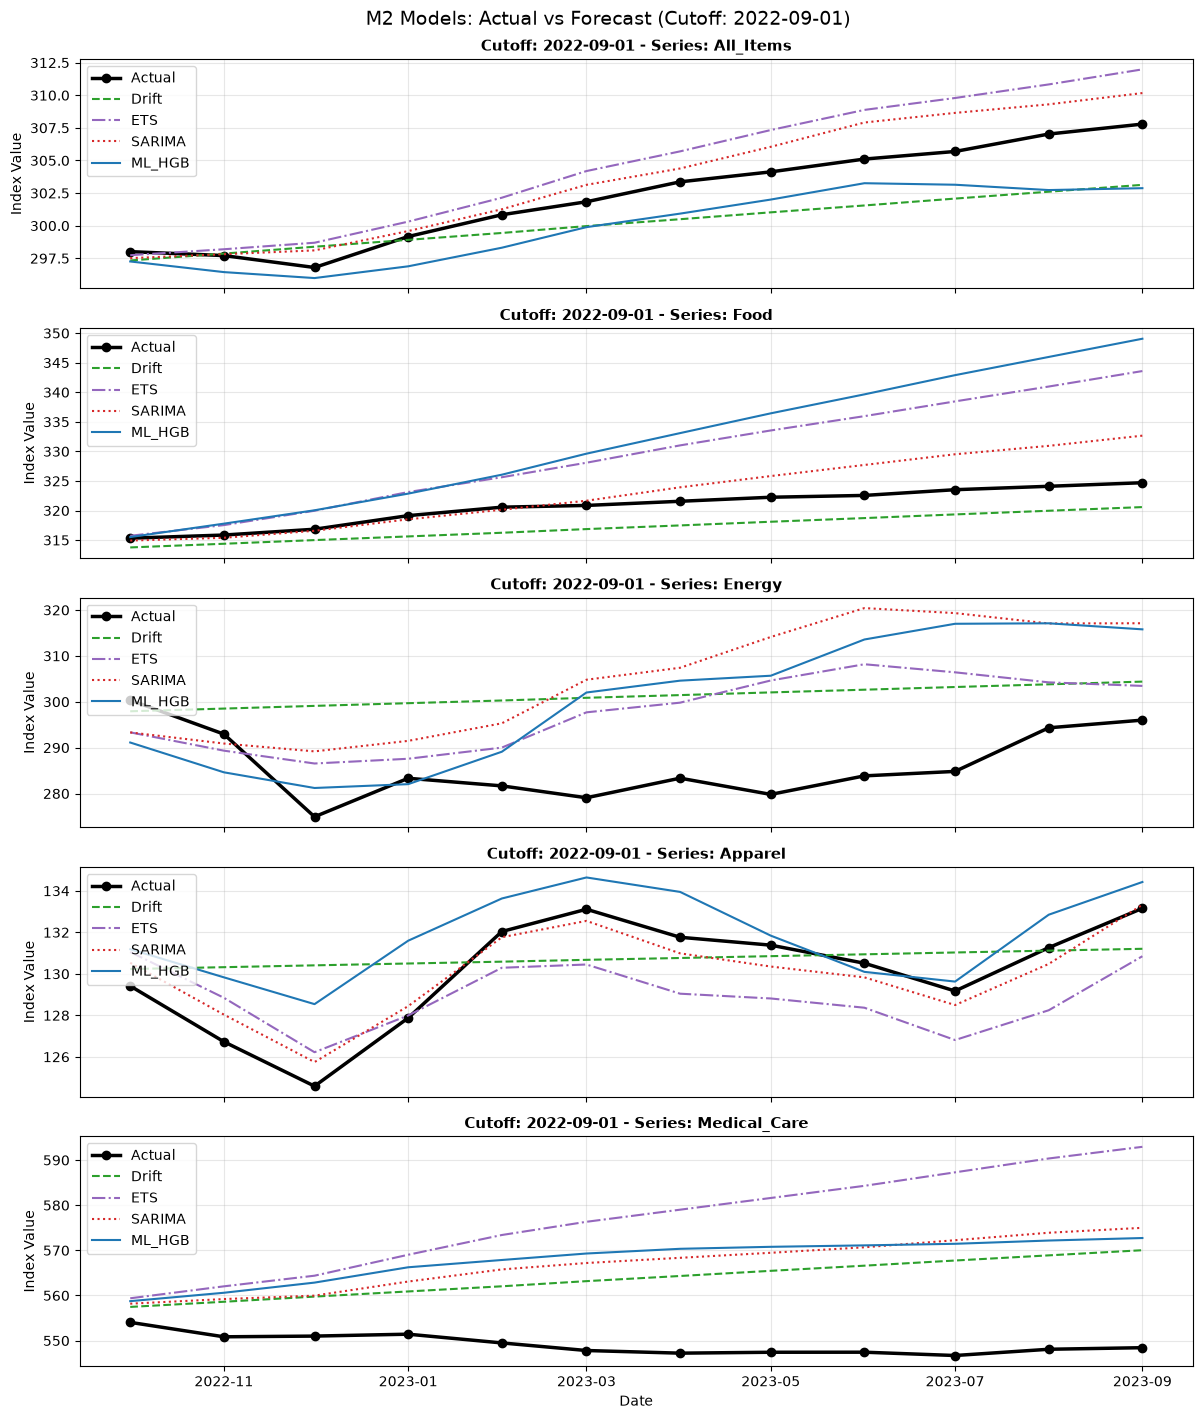

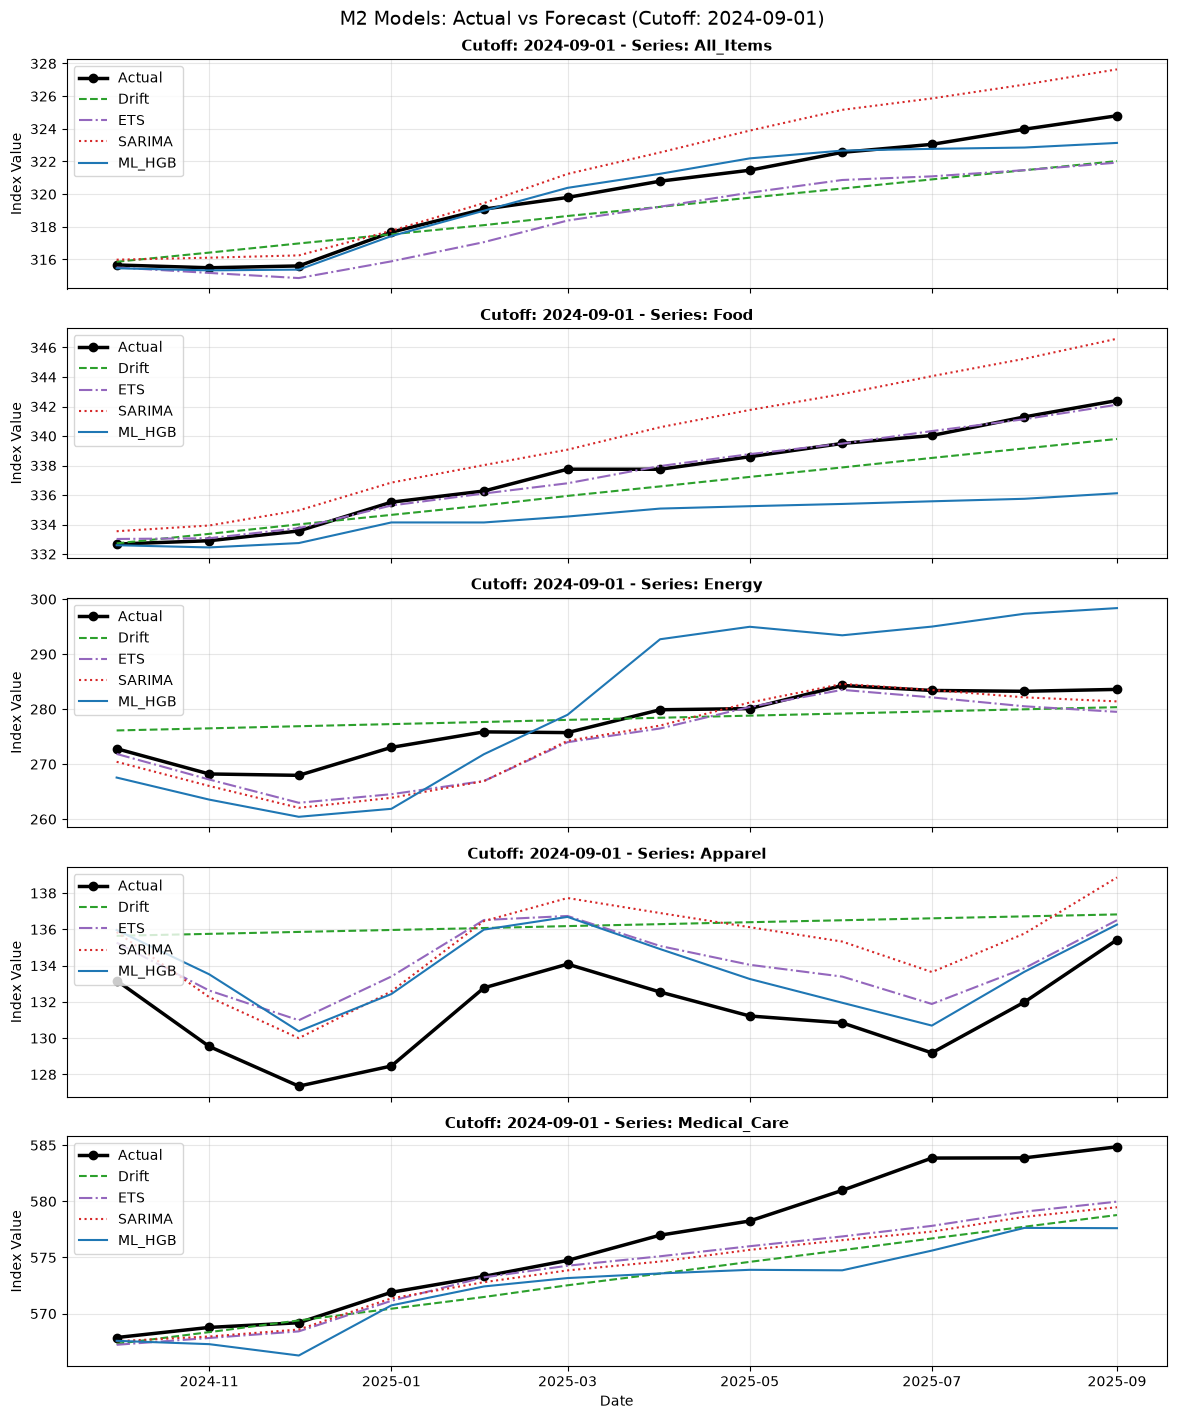

In [15]:
plot_cutoffs = ["2022-09-01", "2024-09-01"]

for cutoff_to_plot in plot_cutoffs:
    fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True)
    
    for i, col in enumerate(df.columns):
        series_data = df[col]
        
        train = series_data.loc[:cutoff_to_plot]
        test_start = pd.to_datetime(cutoff_to_plot) + pd.DateOffset(months=1)
        test_end = pd.to_datetime(cutoff_to_plot) + pd.DateOffset(months=12)
        test = series_data.loc[test_start:test_end]
        
        # Forecasts
        pred_dr = drift_forecast(train, 12)
        pred_ets = ets_forecast_audited(train, 12)
        pred_sarima = sarima_forecast_audited(train, 12)
        pred_ml = ml_hgb_forecast(train, 12)
        
        axes[i].plot(test.index, test, label="Actual", color="black", linewidth=2.5, marker='o')
        axes[i].plot(test.index, pred_dr, label="Drift", color="tab:green", linestyle="--")
        axes[i].plot(test.index, pred_ets, label="ETS", color="tab:purple", linestyle="-.")
        axes[i].plot(test.index, pred_sarima, label="SARIMA", color="tab:red", linestyle=":")
        axes[i].plot(test.index, pred_ml, label="ML_HGB", color="tab:blue", linestyle="-")
        
        axes[i].set_title(f"Cutoff: {cutoff_to_plot} - Series: {col}", fontsize=11, fontweight='bold')
        axes[i].set_ylabel("Index Value")
        axes[i].legend(loc="upper left")
        axes[i].grid(True, alpha=0.3)

    plt.xlabel("Date")
    plt.tight_layout()
    plt.suptitle(f"M2 Models: Actual vs Forecast (Cutoff: {cutoff_to_plot})", y=1.01, fontsize=14)
    
    cutoff_str = cutoff_to_plot.replace("-", "")[:6]
    plt.savefig(os.path.join(PLOTS_DIR, f"05_m2_actual_vs_forecast_cutoff_{cutoff_str}.png"), dpi=300, bbox_inches="tight")
    plt.show()

**Milestone 2 summary:**
- **Convergence:** all 20 ETS and 20 SARIMA fits converged (checked with the optimizer flag and `ConvergenceWarning`).
- **No model beats the best baseline consistently.** The exception is ML_HGB on All_Items (4 of 4 cutoffs, mean MASE 0.255), but its specification was changed after the first run, so this result is not clean evidence.
- **Drift is still the best model on mean MASE for Food (0.217) and Medical_Care (0.468)**, ahead of every statistical and ML model.
- **SARIMA vs ETS is mixed:** SARIMA has lower mean MASE on All_Items, Apparel and Medical_Care; ETS on Energy and Food.
- **Unstable wins:** ETS on Medical_Care wins 2 of 4 cutoffs but has a max MASE of 2.12, worse than the worst result of any baseline on that series.
- **Energy:** every model has max MASE above 1.2; ML_HGB (0.964) is worse than Naive (0.742) on average.

## 6. Milestone 3: Prediction Intervals

### 6.1 Calibration Check (synthetic)

Before using real data, the interval code was checked on 100 synthetic series (trend + seasonality + random walk + noise) where both models are appropriate (`tests/test_calibration.py`, run with `pytest -m slow`). Pooled coverage over 1,200 points:

| Model | 80% interval | 95% interval |
|---|---|---|
| ETS | 0.739 | 0.908 |
| SARIMA | 0.759 | 0.914 |

Coverage is slightly below nominal even here. This is expected, because these intervals do not include parameter estimation uncertainty. It sets the reference for what "normal" under-coverage looks like for this code.

### 6.2 Coverage on Real Data

Coverage is pooled as total covered points divided by total points (235 per model and level), not the mean of per-cutoff coverages. Width is scaled by the same MASE scale so it can be compared across series.

In [16]:
df_m3 = run_interval_backtest(df, CUTOFFS, horizon=HORIZON)
df_m3.to_csv(os.path.join(RESULTS_DIR, "milestone3_interval_results.csv"), index=False)


def pooled(group):
    # Total covered / total points, not the mean of per-cutoff coverages
    return pd.Series({"coverage": group["n_covered"].sum() / group["n_points"].sum(),
                      "n_points": group["n_points"].sum(),
                      "mean_scaled_width": group["scaled_width"].mean()})


df_m3_overall = df_m3.groupby(["model", "level"]).apply(pooled, include_groups=False).reset_index()
expected_points = int(df_m2_results.loc[df_m2_results["model"] == "ETS", "n_points"].sum())
assert (df_m3_overall["n_points"] == expected_points).all(), df_m3_overall
display(df_m3_overall)

df_m3_by_series = df_m3.groupby(["series", "model", "level"]).apply(pooled, include_groups=False).reset_index()
display(df_m3_by_series)

,model,level,coverage,n_points,mean_scaled_width
0,ETS,0.80,0.744681,235.0,1.470668
1,ETS,0.95,0.846809,235.0,2.249192
2,SARIMA,0.80,0.774468,235.0,1.683756
3,SARIMA,0.95,0.910638,235.0,2.575082


,series,model,level,coverage,n_points,mean_scaled_width
0,All_Items,ETS,0.80,0.936170,47.0,1.234958
1,All_Items,ETS,0.95,1.000000,47.0,1.888705
2,All_Items,SARIMA,0.80,0.914894,47.0,0.961044
3,All_Items,SARIMA,0.95,1.000000,47.0,1.469791
4,Apparel,ETS,0.80,0.680851,47.0,2.063510
5,Apparel,ETS,0.95,0.872340,47.0,3.155866
6,Apparel,SARIMA,0.80,0.936170,47.0,3.396124
7,Apparel,SARIMA,0.95,0.978723,47.0,5.193923
8,Energy,ETS,0.80,0.787234,47.0,1.814813
9,Energy,ETS,0.95,0.893617,47.0,2.775517


**Milestone 3 summary:**
- **Overall coverage is close to the synthetic reference:** ETS 80% 0.745 (synthetic 0.739), SARIMA 80% 0.774 (0.759), SARIMA 95% 0.911 (0.914). Most of the overall gap therefore looks like a property of the interval method, not of the data.
- **ETS 95% is the exception:** 0.847 on real data against 0.908 on synthetic data, which is consistent with heavier-than-Gaussian tails. SARIMA 95% shows no such gap.
- **The overall figure hides large differences by series.** All_Items is over-covered (80% intervals cover 0.94 for ETS and 0.91 for SARIMA), while Medical_Care is under-covered (0.57 for both models at 80%, and 0.70 to 0.74 at 95%). Food SARIMA covers 0.60 at 80%.
- **Energy** has the worst point forecasts but good coverage (ETS 0.79, SARIMA 0.85 at 80%), because its intervals are wide (SARIMA scaled width 2.53 vs 0.76 for Medical_Care).
- **Uncertainty:** each series has only 47 test points, and points within one forecast path are correlated. Differences of a few percentage points (for example ETS vs SARIMA on Energy) cannot be distinguished. The Medical_Care gap is large enough to be a likely real problem, but this has not been verified.

## 7. Key Findings

1. **Simple baselines are hard to beat.** Drift has the lowest mean MASE on Food (0.217) and Medical_Care (0.468) among all six models. No statistical or ML model beats the best baseline at every cutoff, except ML_HGB on All_Items (4 of 4), whose specification was changed after the first run.
2. **The best model depends on the series.** SARIMA is best on mean MASE for Apparel (0.832), ETS for Energy (0.677) and ML_HGB for All_Items (0.255), but the gap to the next model is small in each case.
3. **Average error hides instability.** ETS on Medical_Care wins 2 of 4 cutoffs but reaches MASE 2.12 at its worst cutoff, so the worst case should be reported alongside the mean.
4. **Prediction intervals are reasonably calibrated overall but not per series.** Overall 80% coverage is 0.745 (ETS) and 0.774 (SARIMA), close to a synthetic reference, but Medical_Care 80% intervals cover only 0.57 while All_Items intervals are too wide.
5. **For a finance user, an interval should come with its measured coverage.** A label such as "in backtests, this 80% range covered 57% of actual values" prevents over-trusting narrow ranges.

## 8. Limitations

- **Few cutoffs:** four cutoffs per series. Small differences in mean MASE cannot be separated from luck, and no statistical significance test was run.
- **Correlated test points:** errors within one 12-month forecast path are correlated and training windows overlap, so the effective sample size is smaller than 47 points per series.
- **Proxy data:** CPI indices are public price indices, not a company's cost data.
- **Missing month:** 2025-10 has no value in the source data. It is excluded from evaluation, and a forecast from data after 2025-09 would need it to be filled or handled explicitly.
- **ML specification changed after seeing results:** first-run results are reported in section 5.1.
- **Hindsight benchmark:** "best baseline" is chosen per cutoff after the fact, which makes the win counts stricter than a real-world comparison.
- **Univariate models only:** no external drivers (for example oil prices for Energy) are used, so sudden shocks cannot be anticipated.
- **Interval method:** intervals assume the fitted model is correct and ignore parameter uncertainty, which explains part of the under-coverage seen even on synthetic data.